# Saliency explainability

**Why this notebook.** The image models (`c2_train_images.py`) read C0's Grad-CAMs as extra input
streams. This notebook asks what those maps look like where C0 is right and where it is wrong: the
best CNN is picked, its out-of-fold predictions are loaded, and the Grad-CAMs of its inputs (the
query and its nearest counterfactual) are averaged by C0's call, then by quadrant.

**Saliency maps.** `c0_final_predictions.py` stores each Grad-CAM as two (7, 7) maps, each scaled to
[0, 1] by its own max:
* `cam_pos`: evidence C0 sees **for** the disease
* `cam_neg`: evidence C0 sees **against** it (for health)

**Steps**
1. Pick a disease, CF source and K; load the best CNN's out-of-fold predictions.
2. Load the Grad-CAM of every query and of its nearest counterfactual.
3. Average the maps by C0's predicted class.
4. Average them by quadrant (TP / FP / TN / FN), and show wrong minus right per side.

**Figures** follow the thesis style (`code/thesis_style.py`). Set `SAVE_FIGS = True` in the setup
cell to also write each figure as a PDF to `figures/explainability/`.

In [3]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

sys.path.insert(0, os.path.abspath("code"))

DISEASE  = "cardiomegaly"   # effusion | atelectasis | cardiomegaly | consolidation | edema
SOURCE   = "knn_correct_cf"
#SOURCE  = "diffusion_hml_sub20k"
K_VALUES = [1, 10]          # the image models were trained at cf_1 and cf_10
#K_VALUES = [1, 3]    
POLICY   = "ignore"         # C0 uncertainty policy: picks C0_final/multilabel_<policy>


RESULTS = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
C2      = os.path.join(RESULTS, "C2_final_results")
C0_DIR  = os.path.join(RESULTS, "C0_final", f"multilabel_{POLICY}", DISEASE)

import importlib, thesis_style
importlib.reload(thesis_style)     # pick up edits to the style file without a kernel restart
from thesis_style import *
apply()

SAVE_FIGS = False                  # True: every figure is also written as a PDF to FIG_DIR
FIG_DIR   = os.path.join("figures", "explainability")

def save(fig, name):
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, f"{DISEASE}_{SOURCE}_saliency_{name}.pdf"))

## 1. Best CNN

Reads `images/cv_summary.csv` for every K and takes the model with the highest mean AUROC (set
`MODEL` to force one, e.g. `"xi_sal"`). Its five `fold_<i>_predictions.csv` are pooled: each query
sits in the test side of exactly one fold, so this gives every image once.

The query's counterfactuals come from `fold_<i>_slot_probs.npz` (`|`-joined, nearest first); only
the nearest one is kept. Models without a saliency stream write no slot file, so for those the
CF column is empty and only the query maps are shown.

In [4]:
MODEL   = None                   # None = best by AUROC; or a key such as "dual_sal", "xi_sal"
EXCLUDE = {"dual_sal_scalars"}   # prob-free only: this one takes C0's scalars (prob) at the head

summaries = []
for k in K_VALUES:
    s = pd.read_csv(os.path.join(C2, DISEASE, SOURCE, f"cf_{k}", "images", "cv_summary.csv"))
    summaries.append(s.assign(K=k))
summaries = pd.concat(summaries)
summaries = (summaries[~summaries["model"].isin(EXCLUDE)]
             .sort_values("auc_mean", ascending=False, ignore_index=True))
display(summaries[["K", "model", "name", "auc_mean", "auc_std"]])

best = summaries.iloc[0] if MODEL is None else summaries[summaries["model"] == MODEL].iloc[0]
BEST_K, BEST_MODEL = int(best["K"]), best["model"]
print(f"explaining: {best['name']} ({BEST_MODEL}) at K={BEST_K}  "
      f"(AUROC {best['auc_mean']:.4f} ± {best['auc_std']:.4f})")

# Out-of-fold predictions, one row per query, with the nearest CF where the model has one.
pred_dir = os.path.join(C2, DISEASE, SOURCE, f"cf_{BEST_K}", "images", BEST_MODEL)
parts = []
for i in range(5):
    p = pd.read_csv(os.path.join(pred_dir, f"fold_{i}_predictions.csv"))
    p = p.rename(columns={f"{BEST_MODEL}_prob": "cnn_score"}).assign(fold=i)
    slot = os.path.join(pred_dir, f"fold_{i}_slot_probs.npz")
    if os.path.exists(slot):
        z = np.load(slot, allow_pickle=True)
        nearest = pd.Series([str(c).split("|")[0] for c in z["cf_paths"]], index=z["paths"])
        p["cf_path"] = p["path"].map(nearest)
    parts.append(p)
preds = pd.concat(parts, ignore_index=True)
HAS_CF = "cf_path" in preds and preds["cf_path"].notna().all()
print(f"{len(preds):,} queries | C2 target error rate {1 - preds['correct'].mean():.3f} | CF maps: {HAS_CF}")


,K,model,name,auc_mean,auc_std
0,10,dual_sal,Dual Encoder + Saliency,0.916261,0.002622
1,1,dual_sal,Dual Encoder + Saliency,0.914422,0.002899
2,10,dual,Dual Encoder,0.908429,0.002182
3,1,dual,Dual Encoder,0.902720,0.002509
4,10,xi_sal,CNN Xi + Saliency,0.902640,0.003089
5,1,xi_sal,CNN Xi + Saliency,0.902640,0.003089
6,10,cf_sal,CNN CF + Saliency,0.878298,0.003807
7,10,cf,CNN CF,0.876091,0.003147
8,1,cf_sal,CNN CF + Saliency,0.872062,0.003258
9,1,cf,CNN CF,0.863919,0.004315


explaining: Dual Encoder + Saliency (dual_sal) at K=10  (AUROC 0.9163 ± 0.0026)
92,507 queries | C2 target error rate 0.190 | CF maps: True


## 2. Saliency maps

C0's call and label come from `C2_dataset_c0_<disease>.csv`. The Grad-CAMs are looked up the same
way `c2_train_images._load_cam` does: `<C0 dir>/gradcam/<split>/<path with / -> _>.npz`, searched
over the split directories in order. Loading is ~1 ms per map, so a couple of minutes per stream.

In [5]:
CAM_SPLITS = ("C2_dataset", "Original_Test", "CF_levels")
CAM_BASE   = os.path.join(C0_DIR, "gradcam")

def load_cam(img_path):
    """(cam_pos, cam_neg), each (7, 7) in [0, 1]."""
    fname = img_path.replace("/", "_") + ".npz"
    for split in CAM_SPLITS:
        f = os.path.join(CAM_BASE, split, fname)
        if os.path.exists(f):
            z = np.load(f)
            return z["cam_pos"], z["cam_neg"]
    raise FileNotFoundError(f"no Grad-CAM for {img_path!r} under {CAM_BASE}")

def load_cams(paths, desc):
    """Stacked maps for `paths`: (N, 2, 7, 7), channel 0 = for the disease, 1 = against."""
    return np.stack([np.stack(load_cam(p)) for p in tqdm(paths, desc=desc)])

c0 = pd.read_csv(os.path.join(C0_DIR, f"C2_dataset_c0_{DISEASE}.csv"),
                 usecols=["path", "prob", "true", "pred"])
data = preds.merge(c0, on="path", how="left", validate="one_to_one")
assert data["pred"].notna().all(), "some queries have no C0 row"
c0_t = float(open(os.path.join(C0_DIR, "threshold.txt")).read())

CAM_Q  = load_cams(data["path"], "query CAMs")
CAM_CF = load_cams(data["cf_path"], "CF CAMs") if HAS_CF else None

pred = data["pred"].astype(int).values
true = data["true"].astype(int).values
quadrant = np.select([(pred == 1) & (true == 1), (pred == 1) & (true == 0),
                      (pred == 0) & (true == 0)], ["TP", "FP", "TN"], "FN")
print(f"{len(data):,} images | C0 threshold {c0_t:.3f} | maps {CAM_Q.shape}")
display(pd.Series(quadrant).value_counts().rename("n"))

query CAMs:   0%|          | 0/92507 [00:00<?, ?it/s]

CF CAMs:   0%|          | 0/92507 [00:00<?, ?it/s]

92,507 images | C0 threshold 0.160 | maps (92507, 2, 7, 7)


TN    66178
FP    14769
TP     8781
FN     2779
Name: n, dtype: int64

## 3. Average saliency by C0's predicted class

One row per side of C0's call, one column per map: the query's evidence for / against the disease,
then the same for its nearest counterfactual. All panels share one colour scale (the average of
maps in [0, 1]), so brightness is comparable across rows and columns. Maps are drawn at their native
7 x 7 resolution, bilinearly smoothed for display.

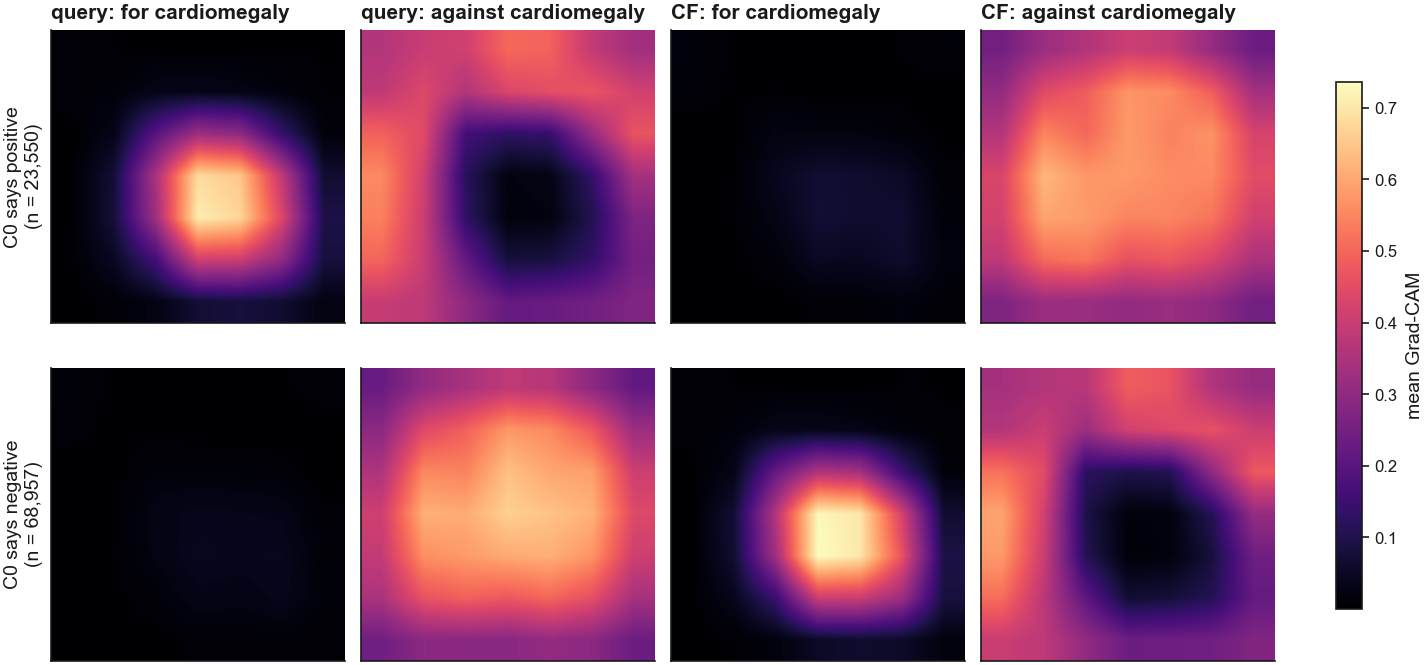

In [6]:
STREAMS = [("query", "for", CAM_Q, 0), ("query", "against", CAM_Q, 1)]
if HAS_CF:
    STREAMS += [("CF", "for", CAM_CF, 0), ("CF", "against", CAM_CF, 1)]

def map_grid(groups, title_fmt, cmap="magma", vmin=None, vmax=None):
    """Rows = groups {label: row mask}, columns = STREAMS; each panel is the group's mean map."""
    means = {g: [cams[m, ch].mean(axis=0) for _, _, cams, ch in STREAMS] for g, m in groups.items()}
    allv  = np.concatenate([np.ravel(v) for v in means.values()])
    vmin  = allv.min() if vmin is None else vmin
    vmax  = allv.max() if vmax is None else vmax
    fig, axes = plt.subplots(len(groups), len(STREAMS), figsize=(FULL, len(groups) * 44 * MM),
                             layout="constrained", squeeze=False)
    for row, (g, m) in zip(axes, groups.items()):
        for ax, (who, direction, _, _), mean in zip(row, STREAMS, means[g]):
            im = ax.imshow(mean, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="bilinear")
            ax.set_xticks([]); ax.set_yticks([])
        row[0].set_ylabel(title_fmt(g, m.sum()))
    for ax, (who, direction, _, _) in zip(axes[0], STREAMS):
        ax.set_title(f"{who}: {direction} {DISEASE}")
    fig.colorbar(im, ax=axes, shrink=0.8, label="mean Grad-CAM")
    return fig, means

SIDES = {"C0 says positive": pred == 1, "C0 says negative": pred == 0}
fig, side_means = map_grid(SIDES, lambda g, n: f"{g}\n(n = {n:,})")
save(fig, "by_predicted_class")
plt.show()

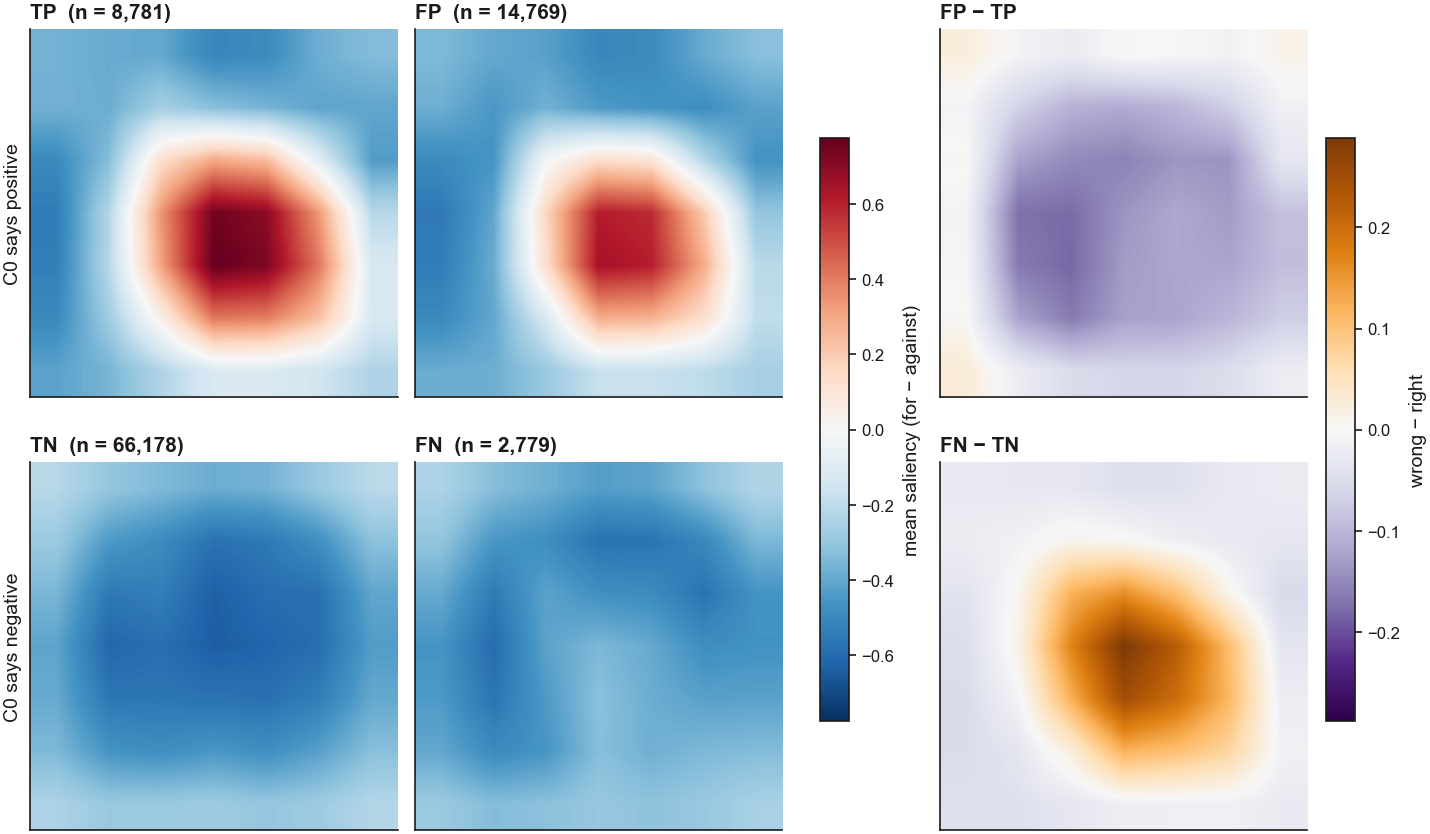

In [ ]:
# One signed map per image: evidence for the disease minus evidence against it
# (the CNN's third input channel, centred at 0). Red = argues for, blue = argues against.
NET_Q = CAM_Q[:, 0] - CAM_Q[:, 1]                       # (N, 7, 7), in [-1, 1]

ROWS  = {"C0 says positive": ("TP", "FP"), "C0 says negative": ("TN", "FN")}   # (right, wrong)
mean  = {q: NET_Q[quadrant == q].mean(axis=0) for q in ["TP", "FP", "TN", "FN"]}
diff  = {w: mean[w] - mean[r] for r, w in ROWS.values()}
lim_m = max(np.abs(m).max() for m in mean.values())
lim_d = max(np.abs(d).max() for d in diff.values())

#Befroe plotting the mean over wuadrant, plot
fig, axes = plt.subplots(2, 3, figsize=(FULL, 110 * MM), layout="constrained")
for row, (side, (r, w)) in zip(axes, ROWS.items()):
    for ax, q in zip(row[:2], (r, w)):
        im_m = ax.imshow(mean[q], cmap="RdBu_r", vmin=-lim_m, vmax=lim_m, interpolation="bilinear")
        ax.set_title(f"{q}  (n = {(quadrant == q).sum():,})")
    im_d = row[2].imshow(diff[w], cmap="PuOr_r", vmin=-lim_d, vmax=lim_d, interpolation="bilinear")
    row[2].set_title(f"{w} − {r}")
    row[0].set_ylabel(side)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im_m, ax=axes[:, :2], shrink=0.7, label="mean saliency (for − against)")
fig.colorbar(im_d, ax=axes[:, 2], shrink=0.7, label="wrong − right")
save(fig, "net_by_quadrant")
plt.show()


average X-rays:   0%|          | 0/4 [00:00<?, ?it/s]

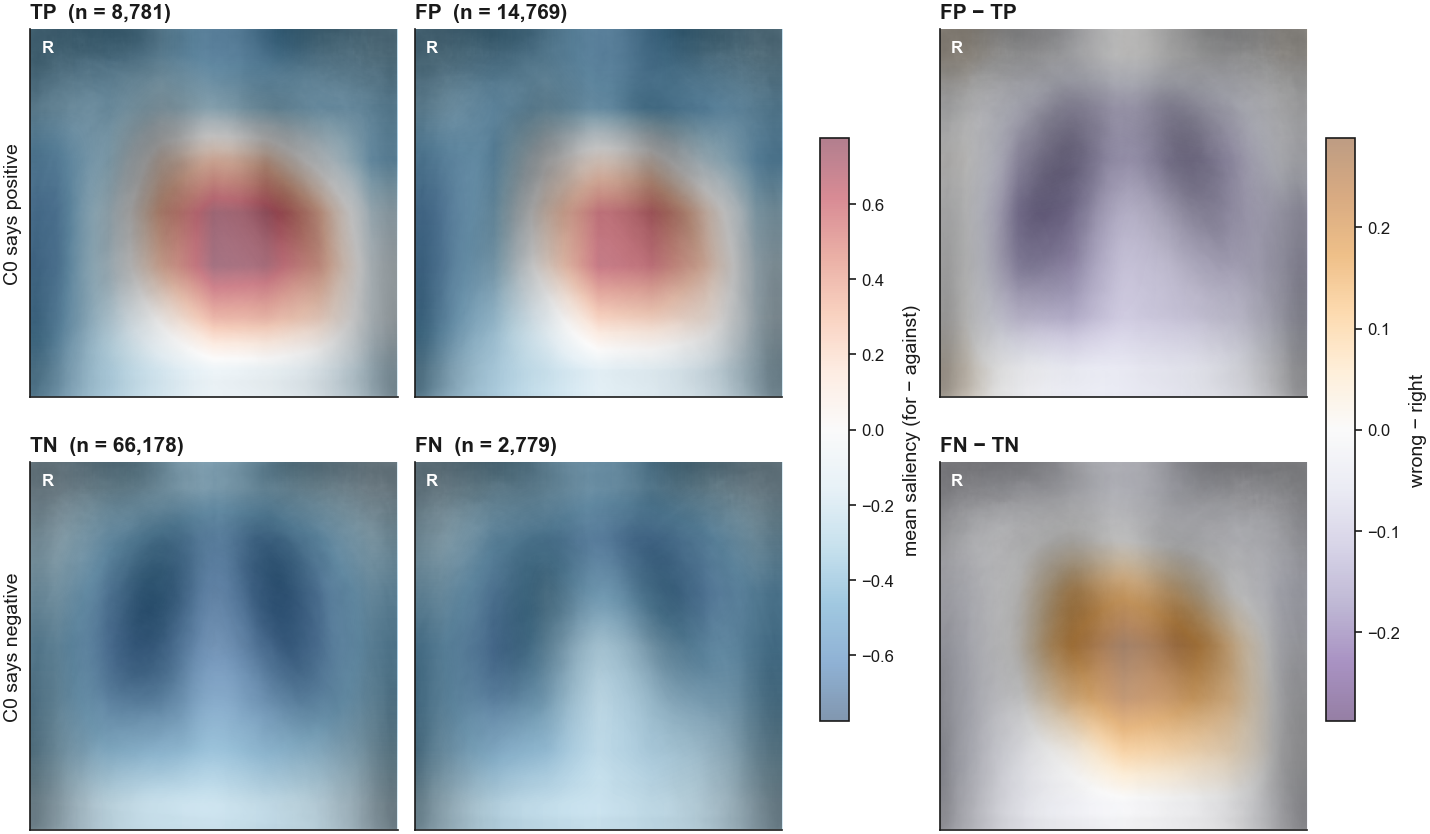

In [8]:
# The signed maps over each quadrant's average X-ray. C0 resizes every image to 224 x 224 (no crop),
# so the 7x7 grid spans the whole image. Opacity follows |value|: near-zero cells let the X-ray through.
import torch, torch.nn.functional as F
from PIL import Image

DATA_ROOT = os.environ.get("THESIS_DATA", "/work3/s251710/thesis_data")
N_AVG     = 100      # images averaged per quadrant for the background (random sample)
SIZE      = 224      # C0's input size
ALPHA = 0.5         # one fixed opacity for the whole map

def overlay(ax, bg, m, lim, cmap):
    """Grey average X-ray with the 7x7 mean map stretched over it (C0 resizes to 224x224, no crop)."""
    ax.imshow(bg, cmap="gray")
    im = ax.imshow(m, cmap=cmap, vmin=-lim, vmax=lim, alpha=ALPHA, interpolation="bilinear",
                   extent=(0, SIZE, SIZE, 0))
    ax.text(0.03, 0.97, "R", transform=ax.transAxes, color="white", fontsize=FS["small"],
            fontweight="bold", va="top")                        # patient's right = image left
    ax.set_xticks([]); ax.set_yticks([])
    return im

rng = np.random.default_rng(0)
def mean_xray(q):
    paths = rng.choice(data["path"].values[quadrant == q], min(N_AVG, (quadrant == q).sum()), replace=False)
    return np.mean([np.asarray(Image.open(os.path.join(DATA_ROOT, p)).convert("L")
                               .resize((SIZE, SIZE), Image.BILINEAR), dtype=np.float32) for p in paths], axis=0)

xray = {q: mean_xray(q) for q in tqdm(["TP", "FP", "TN", "FN"], desc="average X-rays")}


fig, axes = plt.subplots(2, 3, figsize=(FULL, 110 * MM), layout="constrained")
for row, (side, (r, w)) in zip(axes, ROWS.items()):
    for ax, q in zip(row[:2], (r, w)):
        im_m = overlay(ax, xray[q], mean[q], lim_m, "RdBu_r")
        ax.set_title(f"{q}  (n = {(quadrant == q).sum():,})")
    im_d = overlay(row[2], xray[w], diff[w], lim_d, "PuOr_r")  # background: the wrong calls' X-ray
    row[2].set_title(f"{w} − {r}")
    row[0].set_ylabel(side)
fig.colorbar(im_m, ax=axes[:, :2], shrink=0.7, label="mean saliency (for − against)")
fig.colorbar(im_d, ax=axes[:, 2], shrink=0.7, label="wrong − right")
save(fig, "net_by_quadrant_on_xray")
plt.show()


clustering on input, CF: 98 features
C0 says positive: base error rate 0.627, base mean MSP 0.445


,n,error rate,error rate (held-out),mean CNN percentile,mean MSP
group,,,,,
group A,7597,0.567,0.588,0.569,0.513
group B,7485,0.639,0.643,0.471,0.408
group C,8468,0.671,0.689,0.464,0.416


C0 says negative: base error rate 0.040, base mean MSP 0.958


,n,error rate,error rate (held-out),mean CNN percentile,mean MSP
group,,,,,
group A,32107,0.031,0.031,0.564,0.970
group B,26302,0.033,0.033,0.547,0.967
group C,10548,0.088,0.097,0.187,0.902


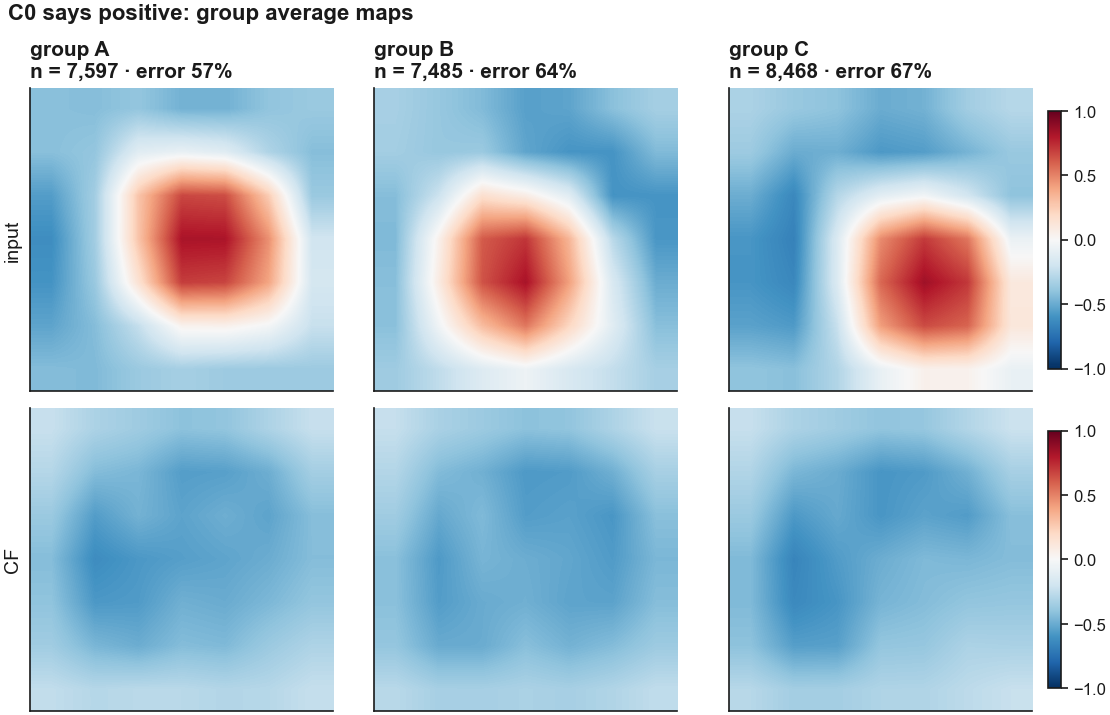

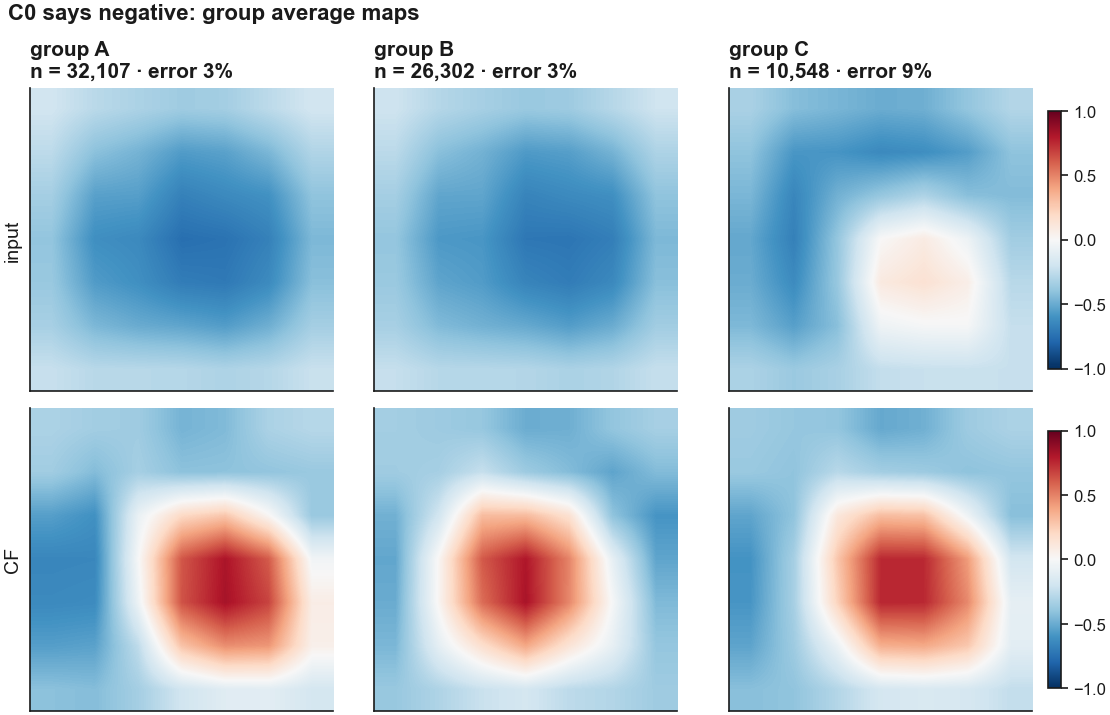

In [30]:
# Groups of saliency maps, per side of C0's call (the saliency version of the attribute groups).
# k-means on three maps per image, as the attribute notebook uses image / CF / delta:
#   input map       for − against, 7 x 7        where C0's evidence sits in the image
#   CF map          the same for its counterfactual
#   input − CF      what changes between them
# Each block is divided by its own overall SD (unit variance per block), so the change map, whose
# range is twice the others', does not dominate the distances. Fit on all folds but HOLDOUT_FOLD,
# which is only assigned, so a group's held-out error rate checks it is not a fitting artefact.
# Groups are named A, B, C... by error rate, A the lowest.
from sklearn.cluster import KMeans
from c2_msp import msp_score

N_CLUSTERS   = 3
HOLDOUT_FOLD = 4

msp = msp_score(data["prob"].values, c0_t, "threshold")        # C0's confidence in its own call
# CNN score as a percentile within C0's call (0 = least trusted): it is class-balanced, so only its rank means anything.
data["cnn_pct"] = data.groupby(pred)["cnn_score"].rank(pct=True).values

# name, maps (N, 7, 7), colour limit, colormap: the blocks the groups are built on, and what the figures draw
NET_CF = CAM_CF[:, 0] - CAM_CF[:, 1] if HAS_CF else None
MAPS   = ([("input", NET_Q, 1, "RdBu_r"), ("CF", NET_CF, 1, "RdBu_r")] if HAS_CF
          else [("input", NET_Q, 1, "RdBu_r")])

blocks = [m.reshape(len(m), -1) for _, m, _, _ in MAPS]
X_MAP  = np.hstack([b / b.std() for b in blocks])               # unit variance per block
print(f"clustering on {', '.join(n for n, *_ in MAPS)}: {X_MAP.shape[1]} features")

def GROUP(k):
    """Cluster id -> display name: 'group A' is the lowest error rate, then B, C..."""
    return f"group {'ABCDEFGHIJ'[N_CLUSTERS - k]}"

cluster, centres = {}, {}          # side -> cluster id per row (1 = most errors); side -> centre per id
for side, (r, w) in ROWS.items():
    p    = int(side == "C0 says positive")
    rows = np.flatnonzero(pred == p)
    fit  = data["fold"].values[rows] != HOLDOUT_FOLD
    km   = KMeans(N_CLUSTERS, n_init=10, random_state=42).fit(X_MAP[rows[fit]])
    lab  = km.predict(X_MAP[rows])
    err  = 1 - data["correct"].values[rows]

    # Renumber 1..N by error rate on the fitting folds, highest first.
    order = pd.Series(err[fit]).groupby(lab[fit]).mean().sort_values(ascending=False).index
    remap = {c: i + 1 for i, c in enumerate(order)}
    cluster[p] = pd.Series([remap[c] for c in lab], index=rows)
    centres[p] = pd.DataFrame(km.cluster_centers_, index=[remap[c] for c in range(N_CLUSTERS)]).sort_index()

    d = pd.DataFrame({"group": cluster[p].values, "error": err, "held_out": ~fit,
                      "cnn": data["cnn_pct"].values[rows], "msp": msp[rows]})
    g = d.groupby("group")
    table = pd.DataFrame({"n":                     g.size(),
                          "error rate":            g["error"].mean(),
                          "error rate (held-out)": d[d.held_out].groupby("group")["error"].mean(),
                          "mean CNN percentile":   g["cnn"].mean(),
                          "mean MSP":              g["msp"].mean()})
    table.index = table.index.map(GROUP)
    print(f"{side}: base error rate {err.mean():.3f}, base mean MSP {msp[rows].mean():.3f}")
    display(table.sort_index().round(3))

# Each group's average maps, one figure per side: rows = input / CF / change, columns = groups
# (lowest error rate on the left).
for side, (r, w) in ROWS.items():
    p = int(side == "C0 says positive")
    fig, axes = plt.subplots(len(MAPS), N_CLUSTERS, squeeze=False, layout="constrained",
                             figsize=(N_CLUSTERS * 40 * MM + 22 * MM, len(MAPS) * 40 * MM + 12 * MM))
    for col, k in enumerate(range(N_CLUSTERS, 0, -1)):
        in_k = cluster[p].index[cluster[p].values == k]
        for rw, (name, M, lim, cmap) in enumerate(MAPS):
            ax = axes[rw, col]
            im = ax.imshow(M[in_k].mean(0), cmap=cmap, vmin=-lim, vmax=lim, interpolation="bilinear")
            ax.set_xticks([]); ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(name)
            if rw == 0:
                ax.set_title(f"{GROUP(k)}\nn = {len(in_k):,} · error {1 - data['correct'].values[in_k].mean():.0%}")
            if col == N_CLUSTERS - 1:
                fig.colorbar(im, ax=ax, shrink=0.85)
    fig.suptitle(f"{side}: group average maps", x=0.01, ha="left")
    save(fig, f"groups_{'pos' if p else 'neg'}")
    plt.show()



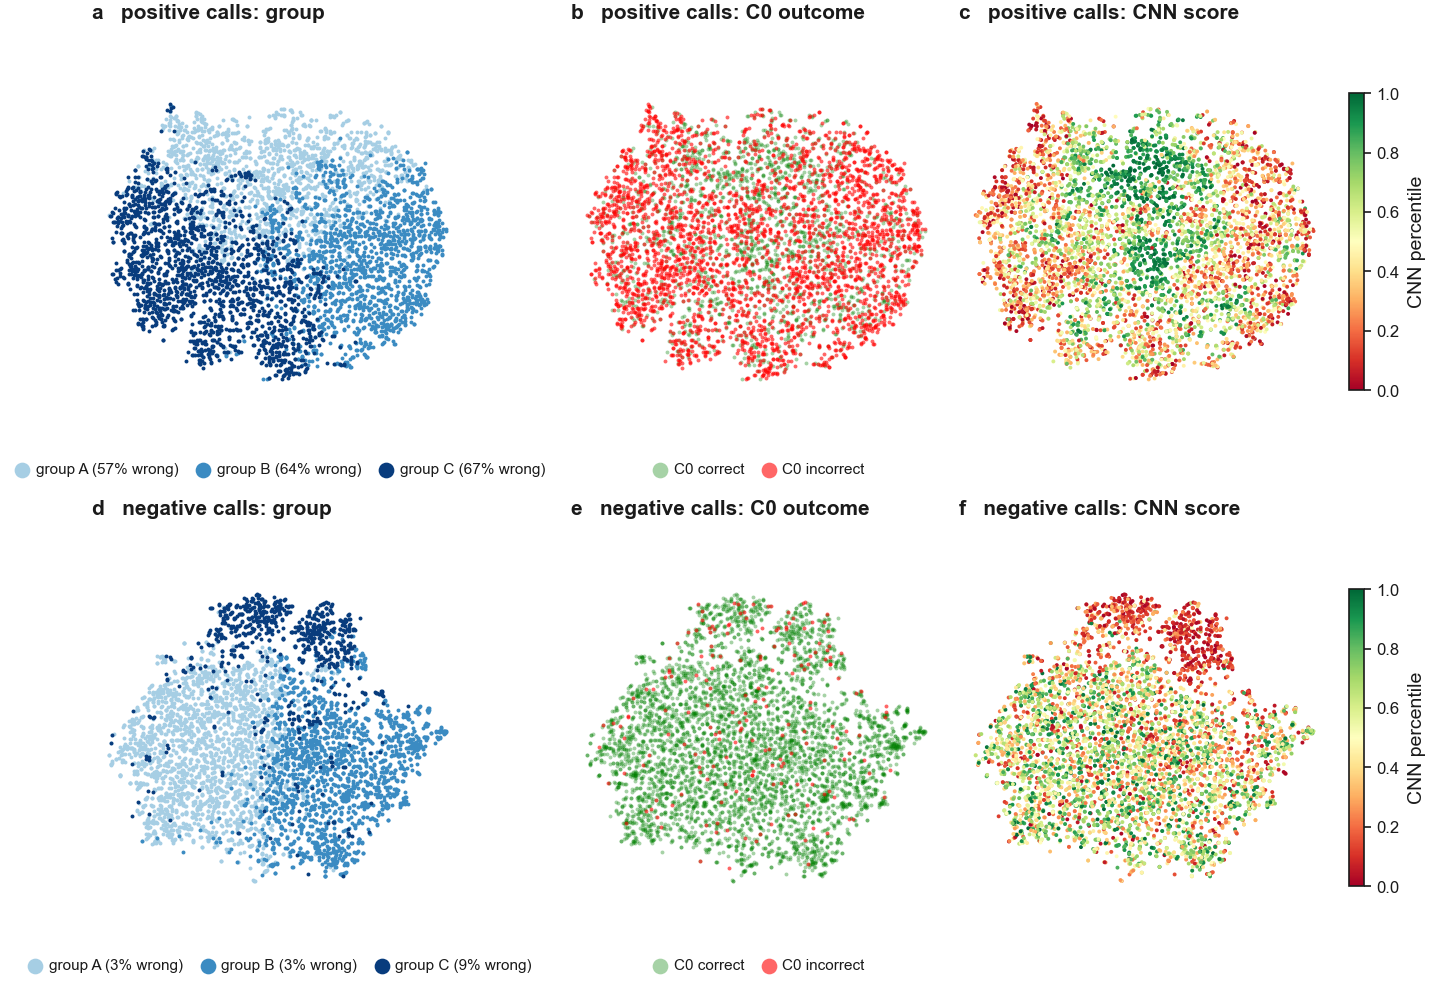

In [31]:
from sklearn.manifold import TSNE

TSNE_N = 5000                                    # images per side (t-SNE is O(n log n) but slow)
GROUP_COLORS = dict(zip(range(N_CLUSTERS, 0, -1),                      # group A (lowest error) light
                        plt.cm.Blues(np.linspace(0.35, 0.95, N_CLUSTERS))))

TSNE_MAP = {}                                    # side -> (sampled rows, 2-D embedding), reused by the case cards

def tsne_position(p, row, n_nn=10):
    """Where `row` sits on side p's map. t-SNE cannot place a new point, so a row outside the
    sample is put at the mean position of its n_nn nearest sampled neighbours in map space."""
    idx, emb = TSNE_MAP[p]
    j = pd.Index(idx).get_indexer([row])[0]
    if j >= 0:
        return emb[j]
    d = np.linalg.norm(X_MAP[np.asarray(idx)] - X_MAP[row], axis=1)
    return emb[np.argsort(d)[:n_nn]].mean(axis=0)

rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 3, figsize=(FULL, 126 * MM), layout="constrained")
letters = iter("abcdef")
for row, p in zip(axes, (1, 0)):                 # positive calls on top, as in the attribute notebook
    rows = cluster[p].index
    idx  = rows[rng.choice(len(rows), min(TSNE_N, len(rows)), replace=False)]
    emb  = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(
        X_MAP[idx])                              # the same signed maps the groups were clustered on
    TSNE_MAP[p] = (idx, emb)
    side = "positive" if p else "negative"
    kw   = dict(s=2, lw=0, rasterized=True)

    # group
    ax = row[0]
    for k in range(N_CLUSTERS, 0, -1):
        m = (cluster[p].loc[idx] == k).values
        err = 1 - data.loc[rows[(cluster[p] == k).values], "correct"].mean()
        ax.scatter(*emb[m].T, color=GROUP_COLORS[k], label=f"{GROUP(k)} ({err:.0%} wrong)", **kw)
    ax.legend(markerscale=4, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=N_CLUSTERS,
              fontsize=FS["tiny"], handletextpad=0.1, columnspacing=0.8)
    ax.set_title(f"{next(letters)}   {side} calls: group")

    # C0 outcome
    ax = row[1]
    ok = (data.loc[idx, "correct"] == 1).values
    ax.scatter(*emb[ok].T, color="green", alpha=0.35, label="C0 correct", **kw)
    ax.scatter(*emb[~ok].T, color="red", alpha=0.6, label="C0 incorrect", **kw)   # errors on top
    ax.legend(markerscale=4, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2,
              fontsize=FS["tiny"], handletextpad=0.1, columnspacing=0.8)
    ax.set_title(f"{next(letters)}   {side} calls: C0 outcome")

    # CNN percentile
    ax = row[2]
    sc = ax.scatter(*emb.T, c=data.loc[idx, "cnn_pct"], cmap="RdYlGn", vmin=0, vmax=1, **kw)
    fig.colorbar(sc, ax=ax, shrink=0.7, label="CNN percentile")
    ax.set_title(f"{next(letters)}   {side} calls: CNN score")

for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_aspect("equal", adjustable="datalim")
save(fig, "tsne_groups")
plt.show()


In [32]:
def load_scales(paths):
    """(scale_pos, scale_neg) per image: the pre-normalisation maxima of the two maps."""
    out = []
    for p in tqdm(paths, desc="CAM scales"):
        fname = p.replace("/", "_") + ".npz"
        f = next(os.path.join(CAM_BASE, s, fname) for s in CAM_SPLITS
                 if os.path.exists(os.path.join(CAM_BASE, s, fname)))
        z = np.load(f)
        out.append((z["scale_pos"], z["scale_neg"]))
    return np.array(out, dtype=np.float32)

RAW_Q = CAM_Q * load_scales(data["path"])[:, :, None, None]   # the actual Grad-CAM magnitudes


CAM scales:   0%|          | 0/92507 [00:00<?, ?it/s]

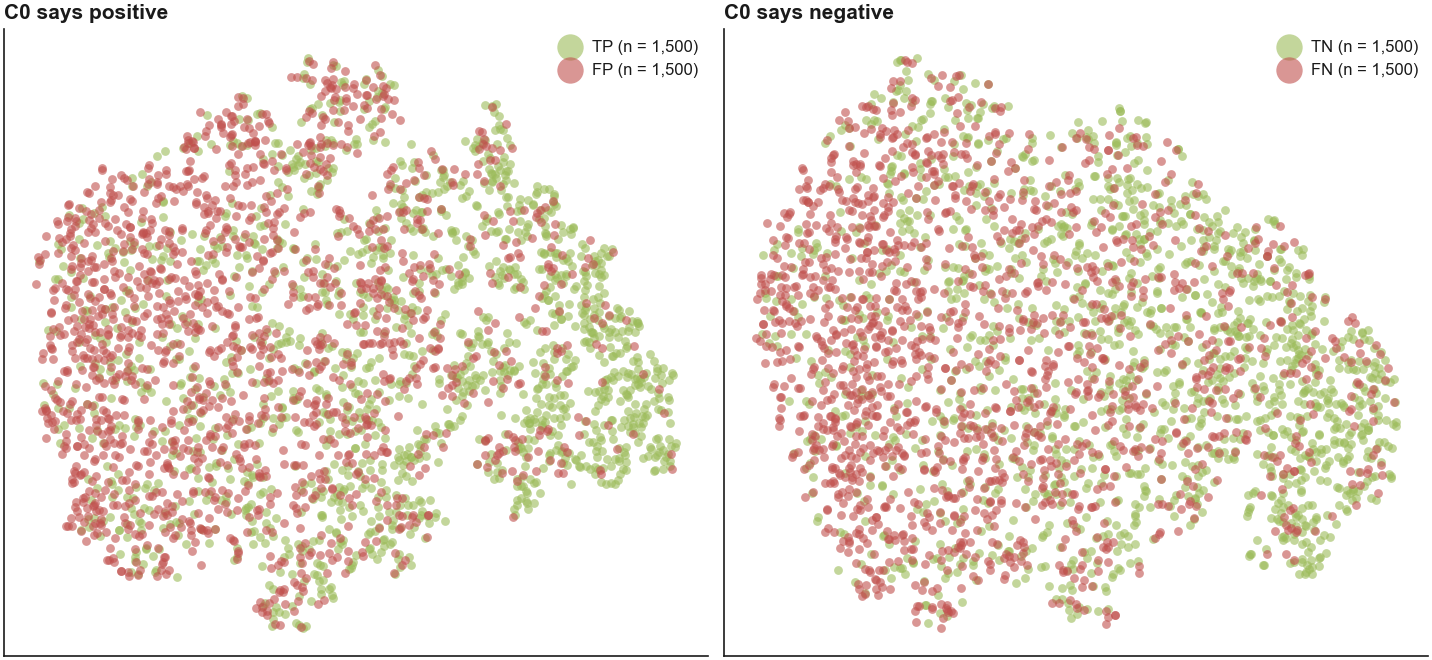

In [33]:
# t-SNE of the saliency maps (as in Herzog et al., Fig. 4A), one embedding per side of C0's call.
# Features: both Grad-CAM channels flattened (2 x 7 x 7 = 98 values, already in [0, 1]); maps are
# small enough to embed directly, no ResNet feature extractor needed.
# Right and wrong calls are sampled equally, so the errors are not buried under the correct calls.
from sklearn.manifold import TSNE
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

N_PER_CLASS = 1500     # right and wrong calls sampled per side (fewer if a quadrant is smaller)
PERPLEXITY  = 50

rng  = np.random.default_rng(0)
tsne = {}                                         # side -> (row indices, 2-D embedding)
for side, (r, w) in ROWS.items():
    idx = np.concatenate([rng.choice(np.flatnonzero(quadrant == q),
                                     min(N_PER_CLASS, (quadrant == q).sum()), replace=False) for q in (r, w)])
    X   = RAW_Q[idx].reshape(len(idx), -1)
    tsne[side] = idx, TSNE(perplexity=PERPLEXITY, init="pca", random_state=0).fit_transform(X)

COLORS = {"TP": "#9BBB59", "TN": "#9BBB59", "FP": "#C0504D", "FN": "#C0504D"}      # right grey, wrong red

fig, axes = plt.subplots(1, 2, figsize=(FULL, 85 * MM), layout="constrained")
for ax, (side, (r, w)) in zip(axes, ROWS.items()):
    idx, emb = tsne[side]
    for q in (r, w):                                                         # wrong drawn on top
        m = quadrant[idx] == q
        ax.scatter(*emb[m].T, s=10, lw=0, alpha=0.6, color=COLORS[q], label=f"{q} (n = {m.sum():,})")
    ax.set_title(side); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(loc="upper right", markerscale=3)
save(fig, "tsne")
plt.show()


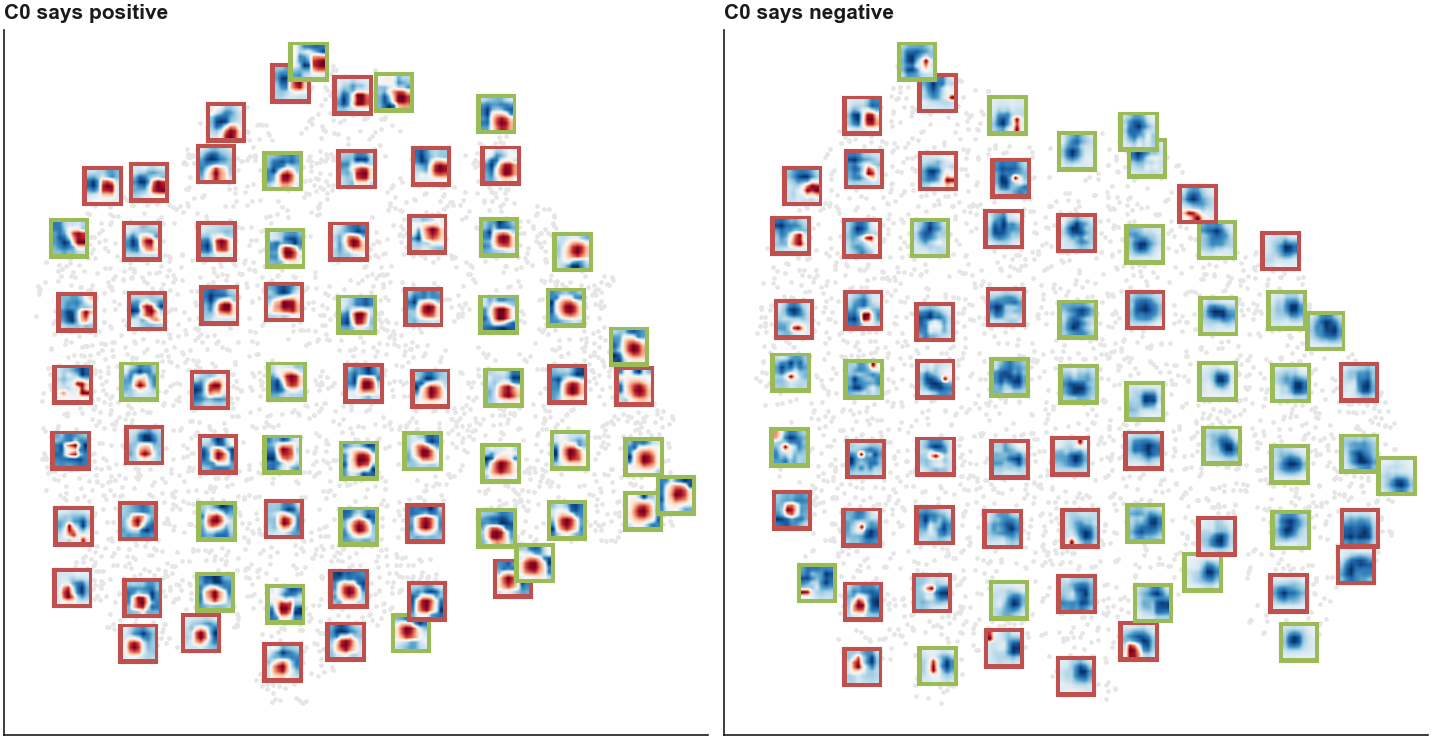

In [34]:
# The same embeddings with the maps themselves drawn on top (signed map: red = for, blue = against).
# One thumbnail per occupied cell of a GRID x GRID raster, taken from the point nearest the cell centre;
# its frame is grey for a correct call and red for a wrong one.
GRID, ZOOM = 9, 1.6

fig, axes = plt.subplots(1, 2, figsize=(FULL, 95 * MM), layout="constrained")
for ax, (side, (r, w)) in zip(axes, ROWS.items()):
    idx, emb = tsne[side]
    ax.scatter(*emb.T, s=3, lw=0, color=HAIR)
    lo, hi = emb.min(0), emb.max(0)
    cell   = np.floor((emb - lo) / (hi - lo + 1e-9) * GRID).astype(int)
    for c in np.unique(cell, axis=0):
        in_c   = np.flatnonzero((cell == c).all(1))
        centre = lo + (c + 0.5) / GRID * (hi - lo)
        j      = in_c[np.argmin(np.linalg.norm(emb[in_c] - centre, axis=1))]
        net    = CAM_Q[idx[j], 0] - CAM_Q[idx[j], 1]
        thumb  = OffsetImage(net, cmap="RdBu_r", norm=plt.Normalize(-1, 1), zoom=ZOOM,
                             interpolation="bilinear")
        ax.add_artist(AnnotationBbox(thumb, emb[j], frameon=True, pad=0.1,
                                     bboxprops=dict(edgecolor=COLORS[quadrant[idx[j]]], lw=2.2)))
    ax.set_title(side); ax.set_xticks([]); ax.set_yticks([])
save(fig, "tsne_thumbnails")
plt.show()


In [45]:
# Case cards: one image through the pipeline, one panel per step, in the order the pipeline runs:
#   a  C0's call: the input X-ray with its saliency map, C0's prediction and probability
#   b  the counterfactual with its own map, and C0's probability for it
#   c  what changes: the input's map minus the counterfactual's
#   d  the group the image is assigned to, on the t-SNE map of the groups (image highlighted)
#   e  similar members: four typical members of the group, with their maps and outcomes
#   f  why it belongs there: the group's average map (the image's map resembles it)
#   g  how the group performs: error rate of every group for this kind of call, its group coloured
#   h  the CNN's quality score for this image against all calls of the same kind
# A row outside the t-SNE sample is placed at the mean position of its 10 nearest sampled
# neighbours (t-SNE cannot embed a new point).
from scipy.stats import gaussian_kde
from sklearn.metrics import roc_auc_score

# C0's probability for each image's counterfactual: a KNN counterfactual is a real C2 image, so it is
# in C0's prediction table; a generated (diffusion) one is in CF_levels/<disease>/cf_pairs.csv.
if HAS_CF and "cf_prob" not in data:
    lut = dict(zip(c0["path"], c0["prob"]))
    pairs = os.path.join(RESULTS, "CF_levels", DISEASE, "cf_pairs.csv")
    if os.path.exists(pairs):
        cp = pd.read_csv(pairs, usecols=["cf_path", "prob"])
        lut.update(zip(cp["cf_path"], cp["prob"]))
    data["cf_prob"] = data["cf_path"].map(lut)
    print(f"C0 probability found for {data['cf_prob'].notna().mean():.1%} of counterfactuals")
LETTERS = "ABCDEFGHIJ"
SCORE_SCOPE = "side" 


def load_xray(path):
    return np.asarray(Image.open(os.path.join(DATA_ROOT, path)).convert("L")
                      .resize((SIZE, SIZE), Image.BILINEAR), dtype=np.float32)

def distances(p, rows):
    """Distance of each row's map to every group centre on side p: (len(rows), N_CLUSTERS), columns = ids."""
    return pd.DataFrame(np.linalg.norm(X_MAP[rows][:, None] - centres[p].values[None], axis=2),
                        index=rows, columns=centres[p].index)

def pick_case(p, group, outcome="correct", n_show=5, cnn="agree"):
    """Row of a typical, clearly assigned held-out image of `group` ('A', 'B'...) on side p.

    cnn="agree": the CNN clearly points the right way (top third of its percentiles for a correct
    call, bottom third for a wrong one); "disagree": clearly the wrong way; None: not used.
    """
    k    = N_CLUSTERS - LETTERS.index(group)
    cand = cluster[p].index[(cluster[p].values == k) & (data["fold"].values[cluster[p].index] == HOLDOUT_FOLD)]
    if outcome is not None:
        cand = cand[data["correct"].values[cand] == (outcome == "correct")]
    if cnn is not None:
        pct, ok = data["cnn_pct"].values[cand], data["correct"].values[cand] == 1
        right   = np.where(ok, pct >= 2 / 3, pct <= 1 / 3)
        cand    = cand[right if cnn == "agree" else ~right & np.where(ok, pct <= 1 / 3, pct >= 2 / 3)]
    assert len(cand), "no candidate matches these filters"
    dist  = distances(p, cand)
    score = pd.DataFrame({"clearness": dist.drop(columns=k).min(axis=1) / dist[k],   # next centre / own centre
                          "distance": dist[k], "outcome": quadrant[cand],
                          "CNN pct": data["cnn_pct"].values[cand], "path": data["path"].values[cand]})
    score = score[score["distance"] <= score["distance"].median()]                 # the typical half
    score = score.sort_values("clearness", ascending=False)
    display(score.head(n_show).round(3))
    return score.index[0]

def tag(ax, text):
    ax.text(0.03, 0.03, text, transform=ax.transAxes, color="white", fontsize=FS["small"],
            fontweight="bold", va="bottom", bbox=dict(facecolor=INK, alpha=0.65, lw=0, pad=1.2))
def c2_kde(ax, rows, row, score_col, pct_col, name):
    """Square KDE of the quality score over `rows`, split by C0 right / wrong, with `row` marked
    (same style as code/c2_plot_score_dist.py)."""
    s_all = data.loc[rows, score_col]
    ok    = (data.loc[rows, "correct"] == 1).values
    x     = np.linspace(0, 1, 500)
    for mask, label, color in [(ok, "C0 correct", "green"), (~ok, "C0 incorrect", "red")]:
        y = gaussian_kde(s_all[mask])(x)
        ax.fill_between(x, y, color=color, alpha=0.2, lw=0)
        ax.plot(x, y, color=color, lw=1, label=label)
    x_img = data.at[row, score_col]
    right = x_img > 0.5                                  # marker in the right half?
    # make line dashed
    ax.axvline(x_img, color=INK, lw=LW["line"]/2, ls="--", zorder=3)
    # "this image" inside the plot, beside the marker; the AUROC note goes to the other side
    ax.text(x_img, 0.97, "this image " if right else " this image", transform=ax.get_xaxis_transform(),
            fontsize=FS["small"], fontweight="bold", va="top", ha="right" if right else "left",
            color=INK, bbox=dict(facecolor="white", alpha=0.85, lw=0, pad=0.8))
    ax.text(0.03 if right else 0.97, 0.97, f"AUROC {roc_auc_score(ok, s_all):.3f}",
            transform=ax.transAxes, ha="left" if right else "right", va="top",
            fontsize=FS["tiny"], color=MUTED)
    ax.set_xlim(0, 1); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_box_aspect(1)
    ax.set_xlabel(f"{name} score, P(correct)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=FS["tiny"],
              handlelength=1.2, columnspacing=0.8)

STAR = "#FFC20A"

def group_errors(ax, p, k, color):
    """Small bar plot: error rate of every group on side p, the image's group k coloured."""
    rows = cluster[p].index
    err  = 1 - data["correct"].values[rows]
    ids  = list(range(N_CLUSTERS, 0, -1))                        # A, B, C...
    vals = [err[cluster[p].values == i].mean() for i in ids]
    y    = np.arange(len(ids))
    ax.barh(y, vals, color=[color if i == k else HAIR for i in ids], height=0.65)
    for yi, v, i in zip(y, vals, ids):
        ax.text(v, yi, f" {v:.0%}", va="center", fontsize=FS["small"],
                fontweight="bold" if i == k else "normal", color=INK)
    ax.axvline(err.mean(), color=GREY, ls="--", lw=LW["ref"])
    ax.text(err.mean(), -0.75, f"all: {err.mean():.0%}", ha="center", va="bottom",
            fontsize=FS["tiny"], color=MUTED)
    ax.set_yticks(y, [GROUP(i).replace("group ", "") for i in ids])
    ax.set_ylim(len(ids) - 0.5, -1.0)
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, max(vals) * 1.35)
    ax.set_xlabel("C0 error rate")

def group_map(ax, p, row, k):
    """The t-SNE map of side p's groups, with `row` highlighted."""
    idx, emb = TSNE_MAP[p]
    for i in range(N_CLUSTERS, 0, -1):
        m = (cluster[p].loc[idx] == i).values
        ax.scatter(*emb[m].T, s=1.2, lw=0, color=GROUP_COLORS[i], alpha=0.8, rasterized=True,
                   label=GROUP(i).replace("group ", ""))
    x, y = tsne_position(p, row)
    ax.scatter([x], [y], marker="*", s=220, color=STAR, edgecolor=INK, lw=1.0, zorder=5)
    ax.annotate("this image", (x, y), xytext=(7, 7), textcoords="offset points",
                fontsize=FS["small"], fontweight="bold", color=INK,
                bbox=dict(facecolor="white", alpha=0.85, lw=0, pad=0.8))
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_aspect("equal", adjustable="datalim"); ax.set_box_aspect(1)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=N_CLUSTERS, markerscale=6,
              fontsize=FS["tiny"], handletextpad=0.1, columnspacing=0.8, title="group",
              title_fontsize=FS["tiny"])
    
def case_card(p, row):
    """One image through the pipeline: a C0's call, b counterfactual, c what changes, d assigned
    group, e precedents (a right and a wrong call of the group, each with its CF), f why it belongs
    there (the group's average map), g how the group performs, h the CNN's quality score."""
    rows  = cluster[p].index
    k     = cluster[p].loc[row]
    in_k  = rows[cluster[p].values == k]
    err   = 1 - data["correct"].values
    side  = "positive" if p else "negative"
    p_img = data.at[row, "prob"]
    net_cf = CAM_CF[row, 0] - CAM_CF[row, 1] if HAS_CF else None

    fig = plt.figure(figsize=(FULL, 132 * MM), layout="constrained")
    top, bottom = fig.subfigures(2, 1, height_ratios=[1, 1.05])
    gt = top.add_gridspec(1, 4)
    # Bottom row: independent sub-figures, so the labels under g and h don't squeeze the images in e.
    sf_e, sf_f, sf_g, sf_h = bottom.subfigures(1, 4, width_ratios=[1.2, 0.75, 0.9, 1.0])

    # a  C0's call
    ax = top.add_subplot(gt[0])
    overlay(ax, load_xray(data.at[row, "path"]), NET_Q[row], 1, "RdBu_r")
    ax.set_title(f"a   C0 says {side}\np = {p_img:.2f}  ·  actual {quadrant[row]}")
    # b  the counterfactual
    ax = top.add_subplot(gt[1])
    if HAS_CF:
        overlay(ax, load_xray(data.at[row, "cf_path"]), net_cf, 1, "RdBu_r")
        cf_p = f"p = {data.at[row, 'cf_prob']:.2f}" if "cf_prob" in data else ""
        ax.set_title(f"b   Counterfactual\n{cf_p}")
    else:
        ax.axis("off"); ax.set_title("b   Counterfactual\n(model has no CF stream)")
    # c  what changes: input map minus CF map
    ax = top.add_subplot(gt[2])
    if HAS_CF:
        im = overlay(ax, load_xray(data.at[row, "path"]), NET_Q[row] - net_cf, 1.5, "PuOr_r")
        top.colorbar(im, ax=ax, shrink=0.7, label="input − CF saliency")
    else:
        ax.axis("off")
    ax.set_title("c   What changes\ninput map − CF map")
    # d  the group it is assigned to
    ax = top.add_subplot(gt[3])
    group_map(ax, p, row, k)
    ax.set_title(f"d   Assigned to {GROUP(k)}")

    # e  precedents: the most typical correct and the most typical wrong call of the group, each
    #    with its counterfactual. Chosen by outcome within the group, never by this image's own
    #    outcome, which is unknown at inference.
    members = in_k[in_k != row]
    d_k     = distances(p, members)[k]
    good, bad = ("TP", "FP") if p else ("TN", "FN")
    axs = sf_e.subplots(2, 2)
    for r, outcome in enumerate((1, 0)):                              # right call on top, wrong below
        cand = d_k[data["correct"].values[d_k.index] == outcome]
        if cand.empty:
            for a_ in axs[r]: a_.axis("off")
            continue
        i = cand.idxmin()                                             # most typical with that outcome
        overlay(axs[r, 0], load_xray(data.at[i, "path"]), NET_Q[i], 1, "RdBu_r")
        tag(axs[r, 0], f"{good if outcome else bad}  p = {data.at[i, 'prob']:.2f}")
        if HAS_CF:
            overlay(axs[r, 1], load_xray(data.at[i, "cf_path"]), CAM_CF[i, 0] - CAM_CF[i, 1], 1, "RdBu_r")
            tag(axs[r, 1], f"CF  p = {data.at[i, 'cf_prob']:.2f}" if "cf_prob" in data else "CF")
        else:
            axs[r, 1].axis("off")
    sf_e.suptitle(f"e   Precedents in {GROUP(k)}: right / wrong", x=0.02, ha="left",
                  fontsize=FS["title"], fontweight="bold")
    # f  why it belongs there: the group's average maps, the same blocks the groups were built on
    axs_f = np.atleast_1d(sf_f.subplots(len(MAPS), 1))
    for ax, (name, M, lim, cmap) in zip(axs_f, MAPS):
        ax.imshow(M[in_k].mean(0), cmap=cmap, vmin=-lim, vmax=lim, interpolation="bilinear")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_ylabel(name, fontsize=FS["tiny"])
    sf_f.suptitle(f"f   Why: {GROUP(k)} maps", x=0.02, ha="left", fontsize=FS["title"], fontweight="bold")

    # g  how the group performs against the others
    ax = sf_g.subplots()
    group_errors(ax, p, k, GROUP_COLORS[k])
    ax.set_title(f"g   How {GROUP(k)} performs")
    # h  the CNN's quality score
    ax = sf_h.subplots()
    score_rows = data.index if SCORE_SCOPE == "all" else rows
    c2_kde(ax, score_rows, row, "cnn_score", "cnn_pct", "CNN")
    ax.set_xlabel(f"CNN score · {'all' if SCORE_SCOPE == 'all' else side} calls")
    ax.set_title(f"h   C2 score on {side}s" if SCORE_SCOPE == "side" else "h   C2 score on all calls")

    pool  = data["cnn_score"].values[np.asarray(score_rows)]
    pct   = (pool < data.at[row, "cnn_score"]).mean()             # this image's percentile in the shown pool
    scope = "all calls" if SCORE_SCOPE == "all" else f"{side} calls"
    trust = f"lower than {1 - pct:.0%} of {scope}" if pct < 0.5 else f"higher than {pct:.0%} of {scope}"


    pct   = data.at[row, "cnn_pct"]
    trust = (f"lower than {1 - pct:.0%} of {side} calls" if pct < 0.5
             else f"higher than {pct:.0%} of {side} calls")
    rest  = rows[cluster[p].values != k]
    rel   = err[in_k].mean() / err[rest].mean()
    more  = f"{rel - 1:.0%} more often" if rel >= 1 else f"{1 - rel:.0%} less often"
    cf_txt = f"counterfactual p = {data.at[row, 'cf_prob']:.2f}  →  " if HAS_CF and "cf_prob" in data else ""
    fig.suptitle(f"C0 says {side} (p = {p_img:.2f})  →  {cf_txt}{GROUP(k)}  →  "
                 f"CNN score {trust}\n"
                 f"In {GROUP(k)}, C0 is wrong {more} than for other {side} calls "
                 f"({err[in_k].mean():.0%} vs {err[rest].mean():.0%})",
                 x=0.01, ha="left", fontweight="normal")
    save(fig, f"case_{side}_{GROUP(k).replace(' ', '')}_{quadrant[row]}")
    plt.show()


,clearness,distance,outcome,CNN pct,path
82153,1.700,5.412,TP,0.853,CheXpert-v1.0-small/train/patient25728/study4/...
80636,1.649,5.364,TP,0.800,CheXpert-v1.0-small/train/patient20681/study3/...
77587,1.603,5.421,TP,0.755,CheXpert-v1.0-small/train/patient11172/study3/...
82879,1.601,5.431,TP,0.792,CheXpert-v1.0-small/train/patient28121/study1/...
80939,1.593,6.170,TP,0.881,CheXpert-v1.0-small/train/patient21843/study8/...


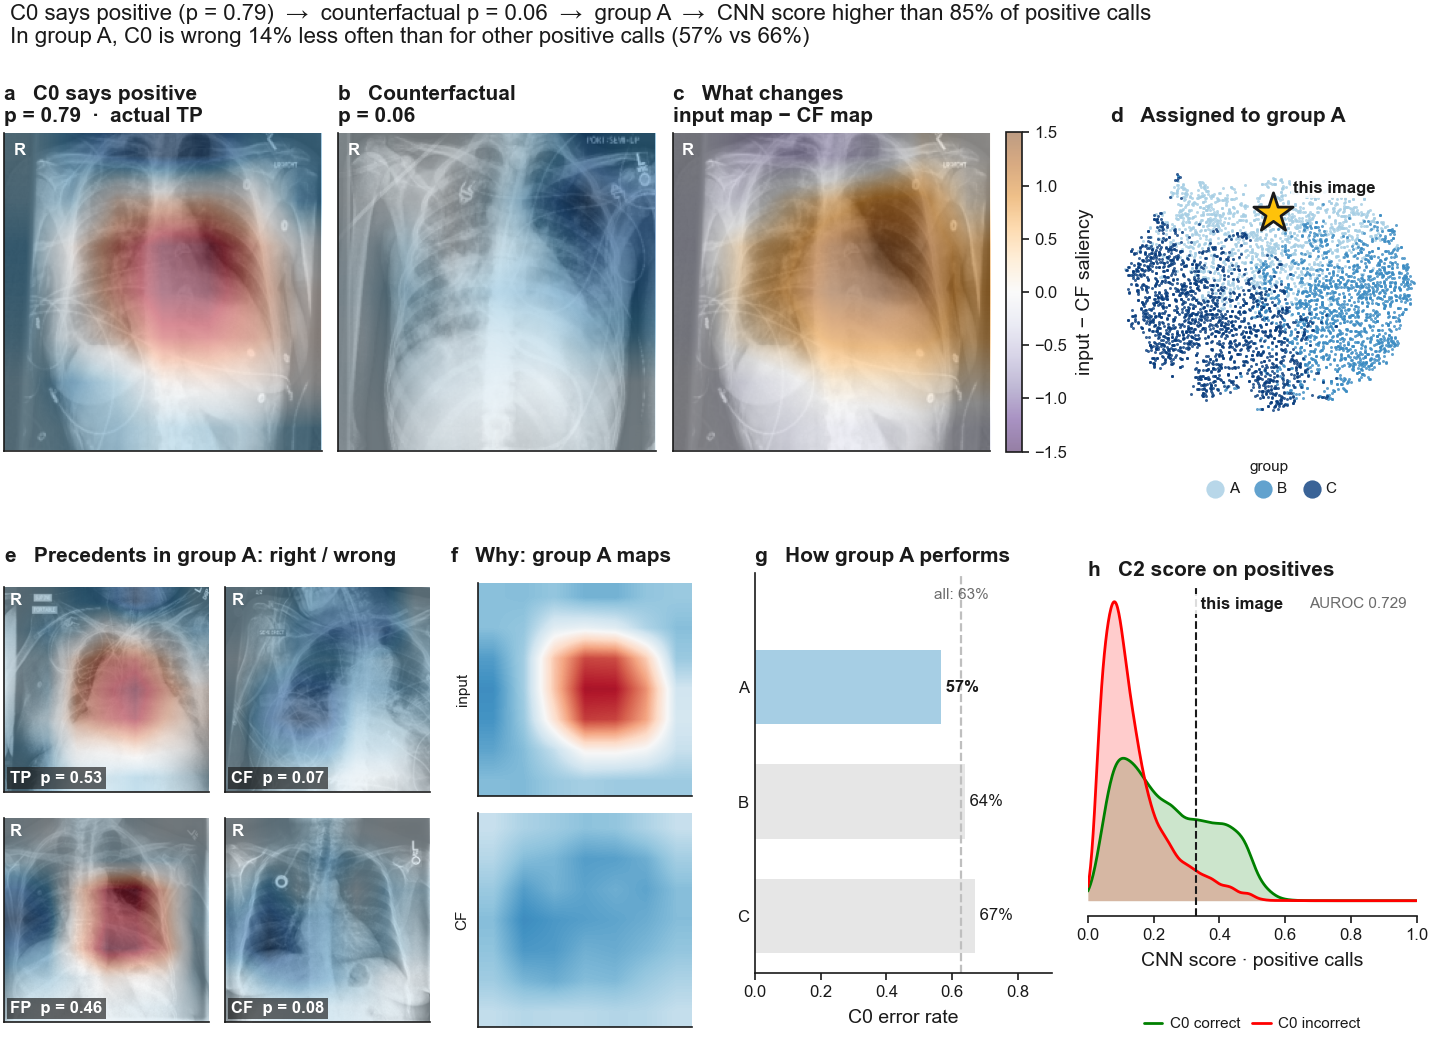

In [46]:
# A reliable case: lowest-error group, C0 was right, and the CNN trusted it.
CASE_SIDE = 1            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, "A", "correct"))


,clearness,distance,outcome,CNN pct,path
75506,2.113,4.333,FP,0.088,CheXpert-v1.0-small/train/patient04141/study1/...
78316,2.107,3.979,FP,0.185,CheXpert-v1.0-small/train/patient13452/study6/...
79313,2.052,4.025,FP,0.304,CheXpert-v1.0-small/train/patient16148/study3/...
85552,1.957,5.407,FP,0.202,CheXpert-v1.0-small/train/patient35831/study2/...
75683,1.925,4.851,FP,0.132,CheXpert-v1.0-small/train/patient04730/study1/...


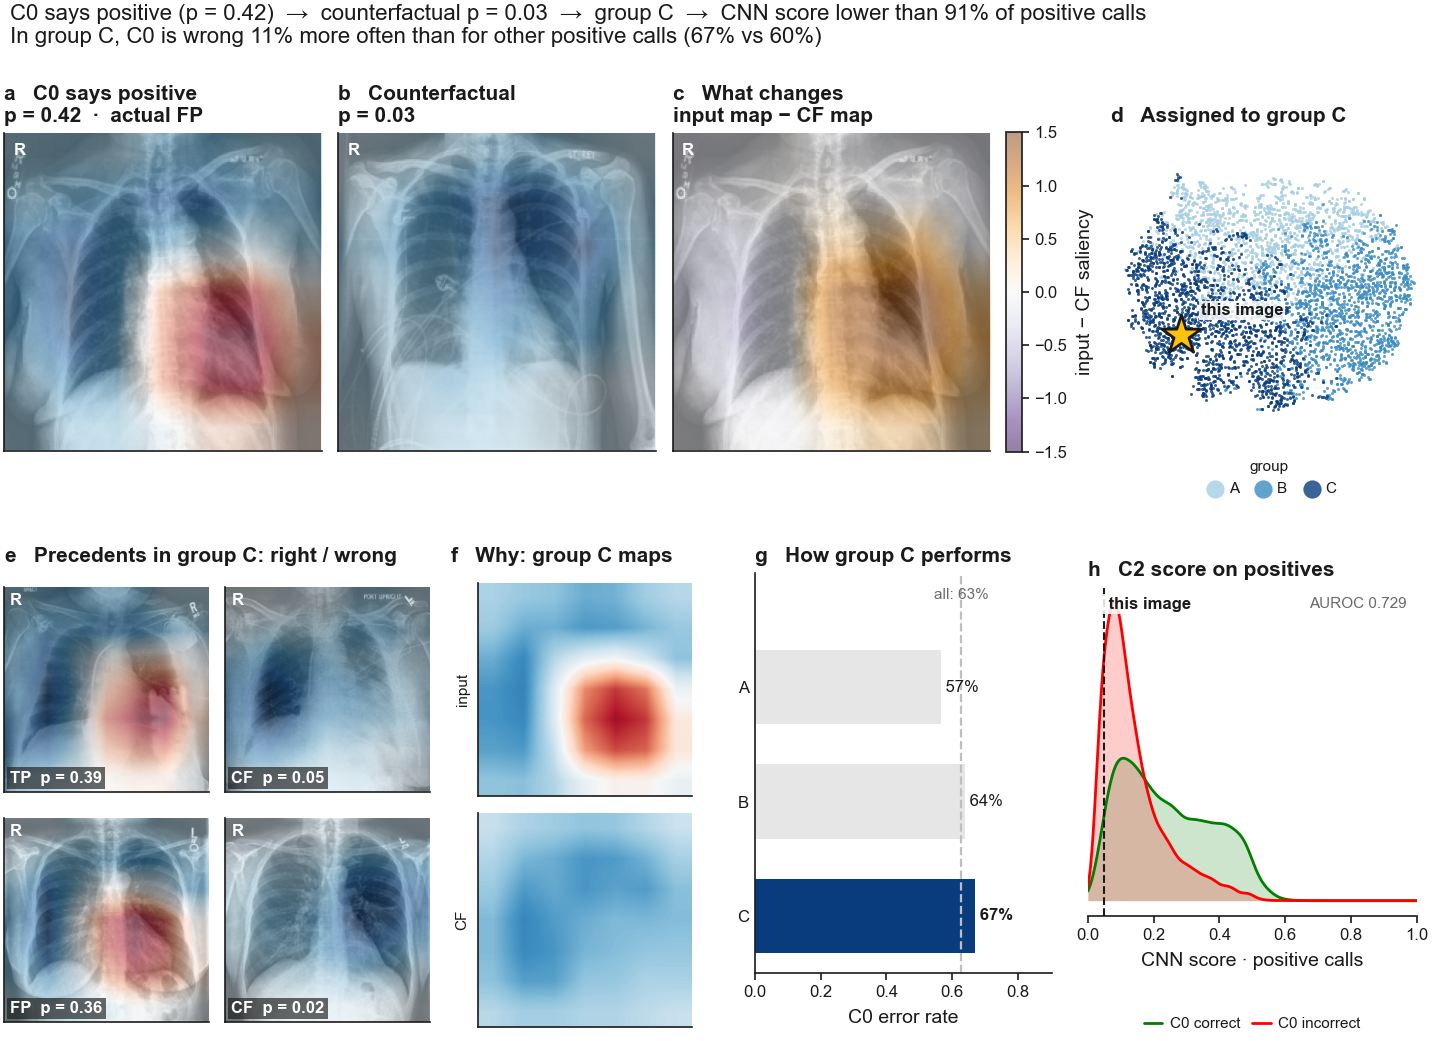

In [47]:
# A risky case: highest-error group, C0 was wrong, and the CNN flagged it.
case_card(CASE_SIDE, pick_case(CASE_SIDE, LETTERS[N_CLUSTERS - 1], "wrong"))


,clearness,distance,outcome,CNN pct,path
76020,2.301,3.007,TN,0.879,CheXpert-v1.0-small/train/patient05624/study1/...
79358,2.213,2.956,TN,0.783,CheXpert-v1.0-small/train/patient16323/study7/...
81869,2.212,3.167,TN,0.885,CheXpert-v1.0-small/train/patient24783/study1/...
81106,2.120,3.101,TN,0.923,CheXpert-v1.0-small/train/patient22241/study1/...
79344,2.094,3.545,TN,0.940,CheXpert-v1.0-small/train/patient16289/study3/...


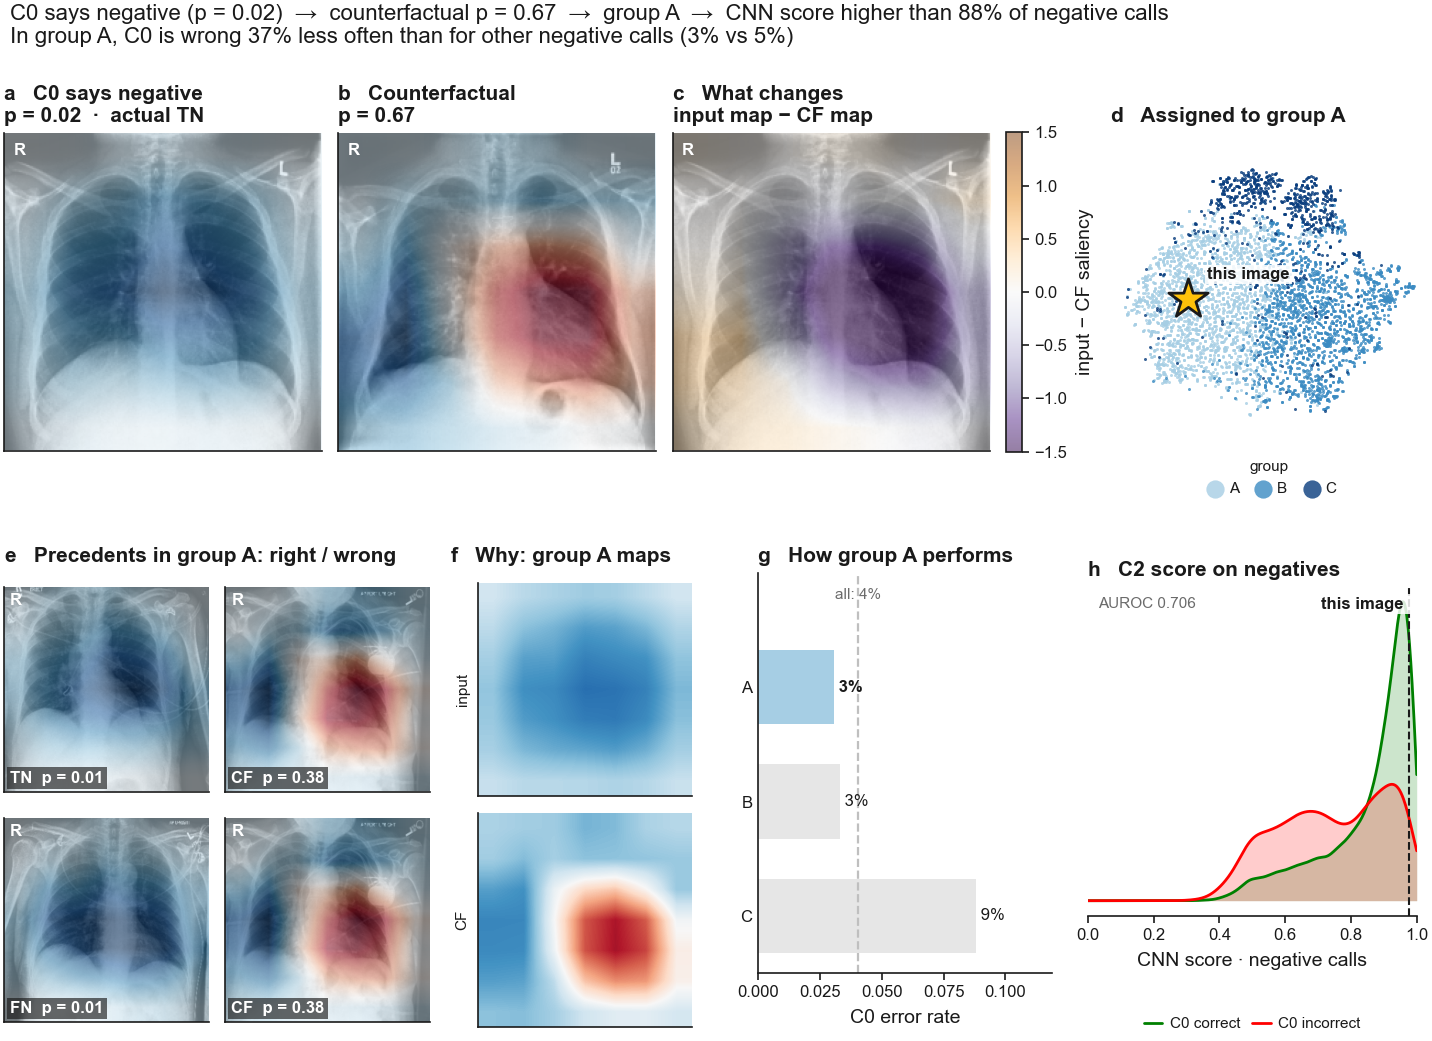

In [48]:
# A reliable case: lowest-error group, C0 was right, and the CNN trusted it.
CASE_SIDE = 0            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, "A", "correct"))

,clearness,distance,outcome,CNN pct,path
77047,1.730,5.952,FN,0.057,CheXpert-v1.0-small/train/patient09593/study15...
77195,1.722,6.047,FN,0.065,CheXpert-v1.0-small/train/patient10093/study4/...
87187,1.670,7.482,FN,0.167,CheXpert-v1.0-small/train/patient39144/study5/...
88371,1.651,7.072,FN,0.042,CheXpert-v1.0-small/train/patient42118/study7/...
74263,1.629,7.181,FN,0.111,CheXpert-v1.0-small/train/patient00047/study3/...


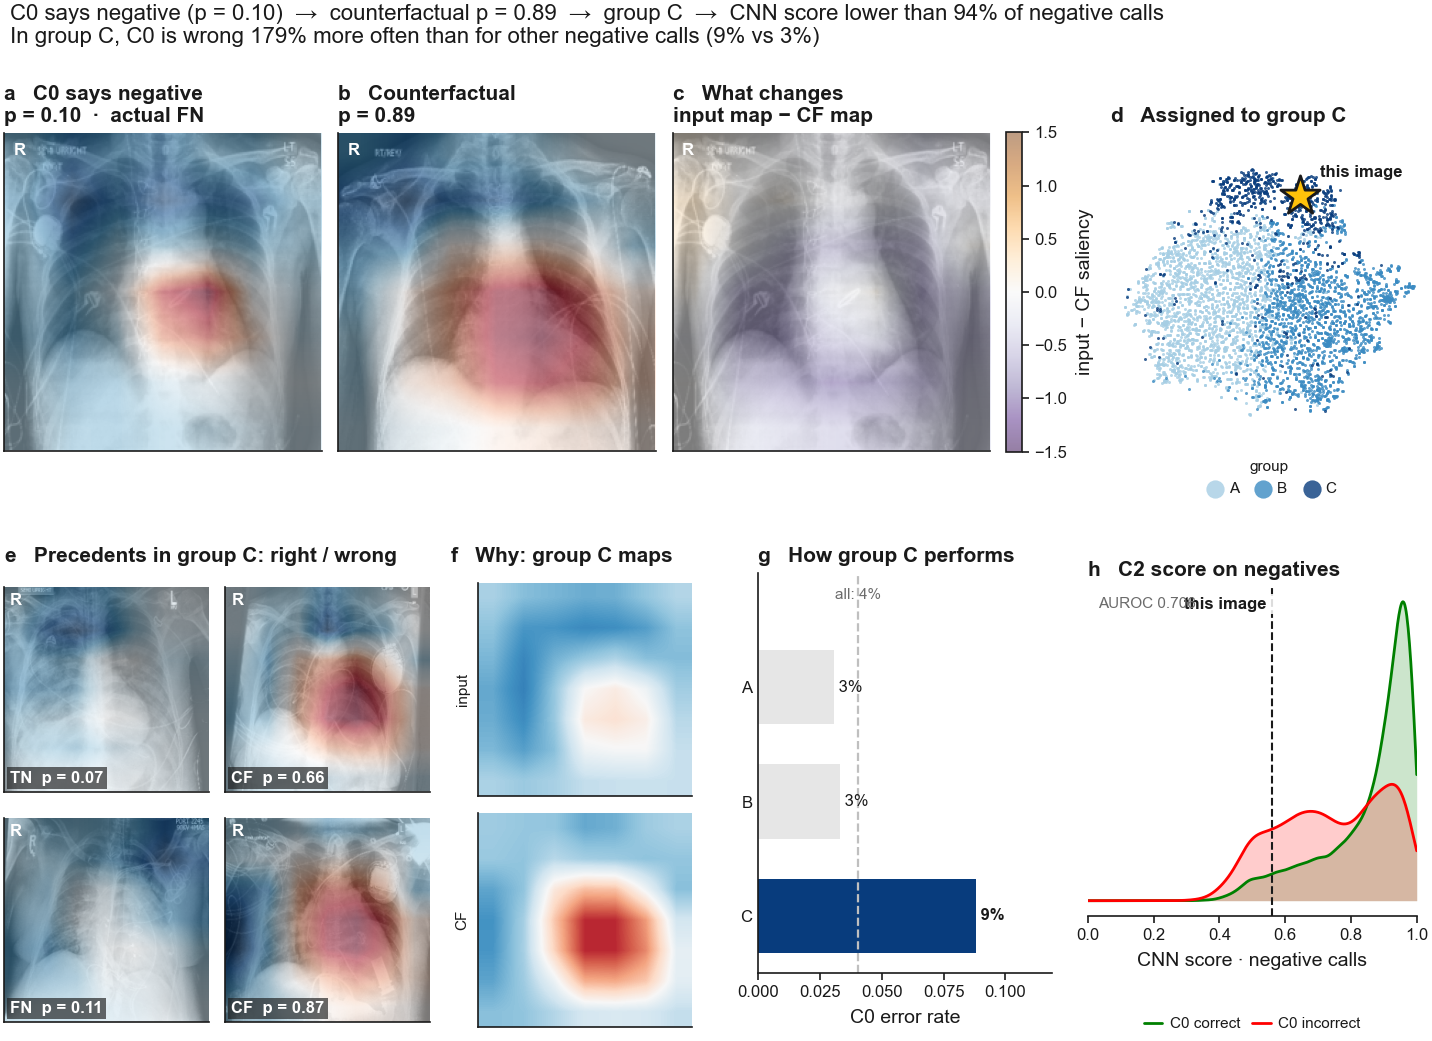

In [50]:
# A reliable case: lowest-error group, C0 was right, and the CNN trusted it.
CASE_SIDE = 0            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, "C", "wrong"))

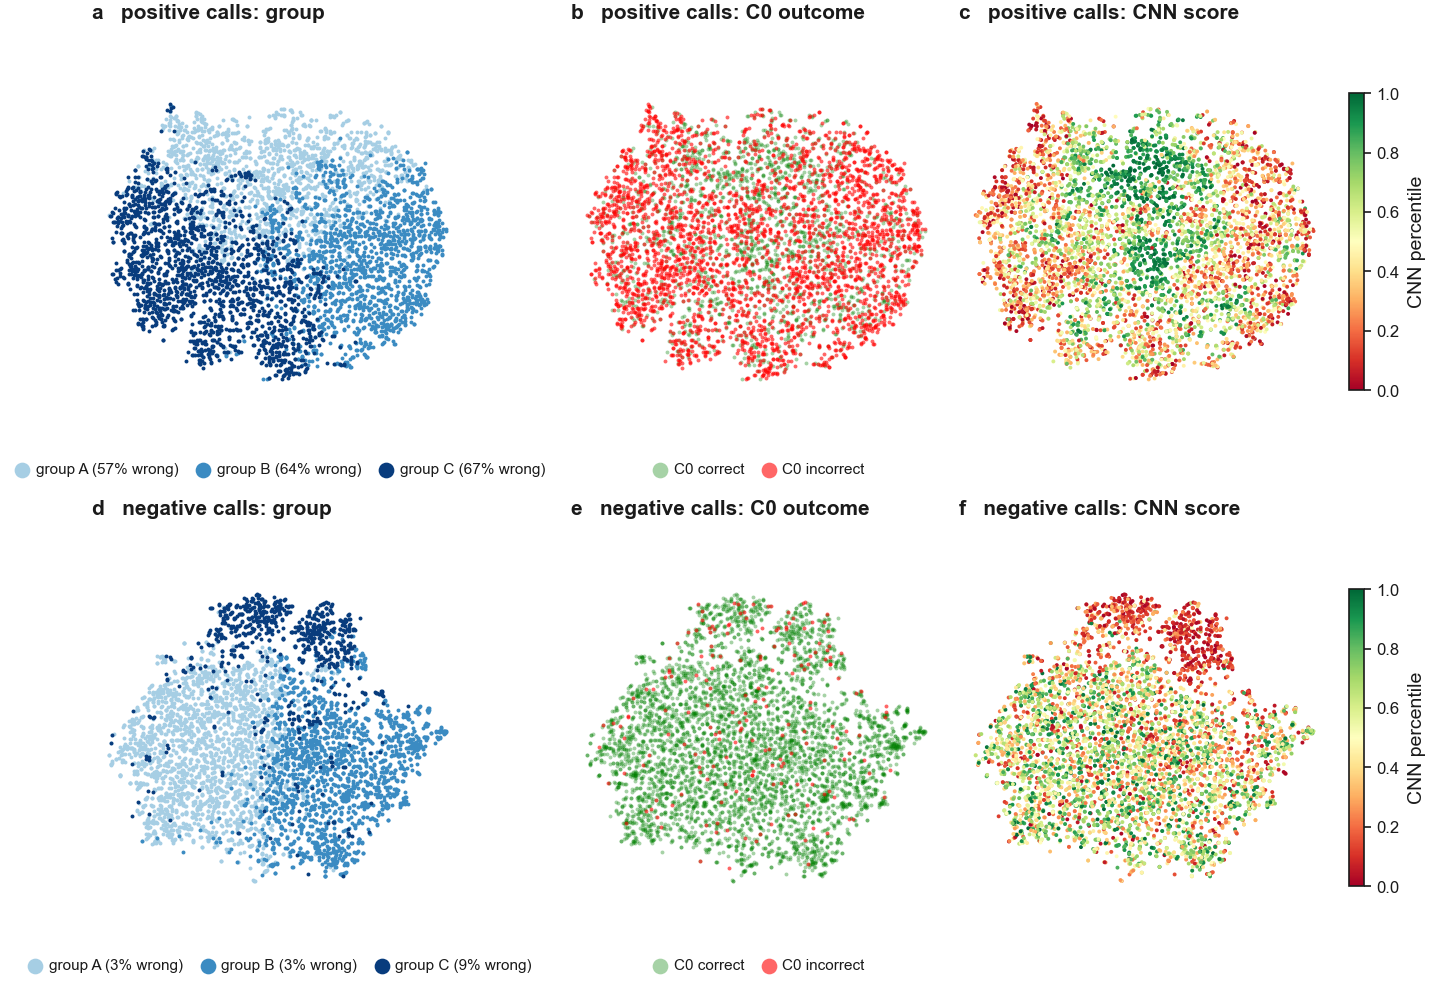

In [ ]:
from sklearn.manifold import TSNE

TSNE_N = 5000                                    # images per side (t-SNE is O(n log n) but slow)
GROUP_COLORS = dict(zip(range(N_CLUSTERS, 0, -1),                      # group A (lowest error) light
                        plt.cm.Blues(np.linspace(0.35, 0.95, N_CLUSTERS))))

TSNE_MAP = {}                                    # side -> (sampled rows, 2-D embedding), reused by the case cards

def tsne_position(p, row, n_nn=10):
    """Where `row` sits on side p's map. t-SNE cannot place a new point, so a row outside the
    sample is put at the mean position of its n_nn nearest sampled neighbours in map space."""
    idx, emb = TSNE_MAP[p]
    j = pd.Index(idx).get_indexer([row])[0]
    if j >= 0:
        return emb[j]
    d = np.linalg.norm(X_MAP[np.asarray(idx)] - X_MAP[row], axis=1)
    return emb[np.argsort(d)[:n_nn]].mean(axis=0)

rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 3, figsize=(FULL, 126 * MM), layout="constrained")
letters = iter("abcdef")
for row, p in zip(axes, (1, 0)):                 # positive calls on top, as in the attribute notebook
    rows = cluster[p].index
    idx  = rows[rng.choice(len(rows), min(TSNE_N, len(rows)), replace=False)]
    emb  = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(
        X_MAP[idx])                              # the same signed maps the groups were clustered on
    TSNE_MAP[p] = (idx, emb)
    side = "positive" if p else "negative"
    kw   = dict(s=2, lw=0, rasterized=True)

    # group
    ax = row[0]
    for k in range(N_CLUSTERS, 0, -1):
        m = (cluster[p].loc[idx] == k).values
        err = 1 - data.loc[rows[(cluster[p] == k).values], "correct"].mean()
        ax.scatter(*emb[m].T, color=GROUP_COLORS[k], label=f"{GROUP(k)} ({err:.0%} wrong)", **kw)
    ax.legend(markerscale=4, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=N_CLUSTERS,
              fontsize=FS["tiny"], handletextpad=0.1, columnspacing=0.8)
    ax.set_title(f"{next(letters)}   {side} calls: group")

    # C0 outcome
    ax = row[1]
    ok = (data.loc[idx, "correct"] == 1).values
    ax.scatter(*emb[ok].T, color="green", alpha=0.35, label="C0 correct", **kw)
    ax.scatter(*emb[~ok].T, color="red", alpha=0.6, label="C0 incorrect", **kw)   # errors on top
    ax.legend(markerscale=4, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2,
              fontsize=FS["tiny"], handletextpad=0.1, columnspacing=0.8)
    ax.set_title(f"{next(letters)}   {side} calls: C0 outcome")

    # CNN percentile
    ax = row[2]
    sc = ax.scatter(*emb.T, c=data.loc[idx, "cnn_pct"], cmap="RdYlGn", vmin=0, vmax=1, **kw)
    fig.colorbar(sc, ax=ax, shrink=0.7, label="CNN percentile")
    ax.set_title(f"{next(letters)}   {side} calls: CNN score")

for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_aspect("equal", adjustable="datalim")
save(fig, "tsne_groups")
plt.show()
